In [1]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = xr.open_dataset("../data/sst_baja_1981_2026.nc")

In [3]:
ds

<xarray.Dataset> Size: 17MB
Dimensions:  (time: 540, lat: 58, lon: 66)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Data variables:
    sst      (time, lat, lon) float32 8MB ...
    ssta     (time, lat, lon) float32 8MB ...
Attributes: (12/15)
    description:                ENSO related variables. Monthly. Oceanic Nino...
    title:                      Monthly sea surface temperature and SST anoma...
    summary:                    Monthly sea surface temperature (SST) and sea...
    source:                     NOAA Optimum Interpolation Sea Surface Temper...
    institution:                CICESE
    Conventions:                CF-1.8
    ...                         ...
    geospatial_lat_min:         21.125
    geospatial_lat_max:         35.375
    geospatial_lon_min:         -124.875
    geospatial_lon_max:         -108.625
    geospatial_lat_resolution:  0.25
    geospatial_lon_resolution:  0.25

In [4]:
ds.sst

<xarray.DataArray 'sst' (time: 540, lat: 58, lon: 66)> Size: 8MB
[2067120 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [5]:
type(ds)

xarray.core.dataset.Dataset

In [6]:
type(ds.sst)

xarray.core.dataarray.DataArray

In [7]:
ds.sst.shape


(540, 58, 66)

In [8]:
ds.sst.attrs


{'long_name': 'Monthly mean sea surface temperature',
 'standard_name': 'sea_surface_temperature',
 'units': 'degree_Celsius',
 'source': 'NOAA OISST V2.1',
 'cell_methods': 'time: mean'}

In [9]:
ds.sst.isel(time=0)

<xarray.DataArray 'sst' (lat: 58, lon: 66)> Size: 15kB
[3828 values with dtype=float32]
Coordinates:
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
    time     datetime64[ns] 8B 1981-09-01
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [10]:
ds.sst.sel(time="1997-12")

<xarray.DataArray 'sst' (time: 1, lat: 58, lon: 66)> Size: 15kB
[3828 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 1997-12-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [11]:
ds.sst.sel(time=["1997-12","1998-12"])

<xarray.DataArray 'sst' (time: 2, lat: 58, lon: 66)> Size: 31kB
[7656 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 16B 1997-12-01 1998-12-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [12]:
ds.sst.isel(lon=slice(4,19))

<xarray.DataArray 'sst' (time: 540, lat: 58, lon: 15)> Size: 2MB
[469800 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 60B -123.9 -123.6 -123.4 ... -120.9 -120.6 -120.4
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [13]:
ds.sst.shape

(540, 58, 66)

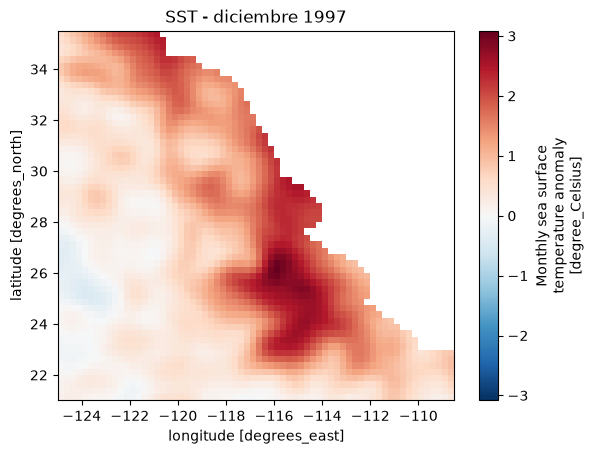

In [17]:
ds.ssta.sel(time="1997-12").plot()
plt.title('SST - diciembre 1997')
plt.show()

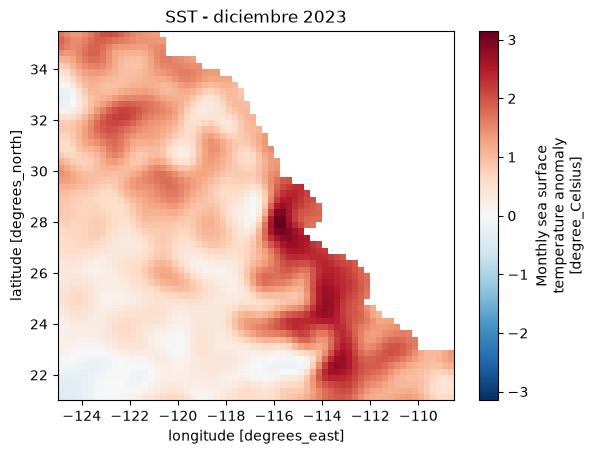

In [18]:
ds.ssta.sel(time="2023-12").plot()
plt.title('SST - diciembre 2023')
plt.show()

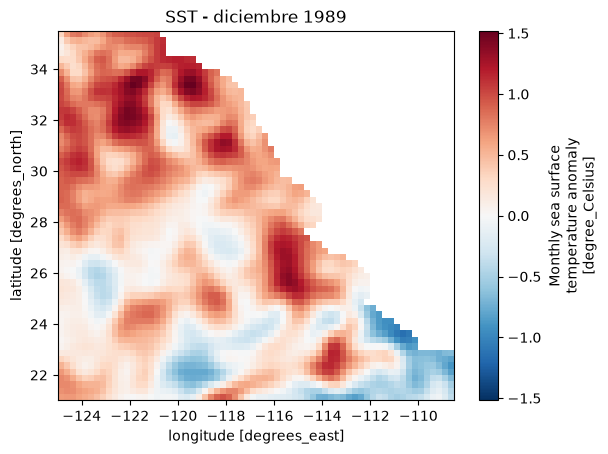

In [19]:
ds.ssta.sel(time="1989-12").plot()
plt.title('SST - diciembre 1989')
plt.show()

In [44]:
ssta_mean = ds.ssta.mean(dim=('lat','lon'), skipna=True)

In [21]:
ssta_mean

<xarray.DataArray 'ssta' (time: 540)> Size: 2kB
array([-2.37494111e-01, -5.40169060e-01, -1.79166093e-01,  5.99263199e-02,
       -1.61783844e-01, -1.78843021e-01,  3.00070662e-02,  2.70233393e-01,
        1.55271634e-01, -5.49857914e-01, -7.19233990e-01, -5.78685820e-01,
       -1.24248534e-01, -4.15379822e-04,  3.53220195e-01,  5.07466316e-01,
        5.18841982e-01,  8.06495488e-01,  7.64832735e-01,  6.27807796e-01,
        1.58167064e-01,  6.39491621e-03, -1.93227753e-01,  3.36776078e-01,
        5.09085715e-01,  9.95600820e-01,  1.00861561e+00,  4.44950908e-01,
        3.53603214e-01,  4.54594284e-01,  2.41201788e-01, -1.19668178e-01,
       -2.56505489e-01, -2.54707992e-01, -4.68262248e-02,  1.98971316e-01,
        4.35364634e-01, -2.17254572e-02, -4.11490232e-01, -5.13221025e-01,
       -5.99809766e-01, -5.67858458e-01, -6.34811819e-01, -4.17231649e-01,
       -6.12196028e-01, -3.92144084e-01,  4.96980727e-01,  2.34920800e-01,
        4.21039045e-01,  3.37391734e-01, -2.96867132e-01, -4.12461102e-01,
        4.98505868e-02,  2.68243492e-01,  2.67679811e-01,  3.39075714e-01,
        3.15292537e-01,  2.28611648e-01,  5.59176244e-02, -2.10662000e-02,
       -3.98543358e-01, -4.73016679e-01, -4.12843972e-01,  1.48443997e-01,
       -1.28040001e-01, -1.79525018e-01, -3.40197295e-01, -2.66967535e-01,
       -7.76457191e-02, -4.99256104e-01, -7.00155377e-01, -4.41712260e-01,
       -2.25879118e-01,  2.85151124e-01,  4.41357315e-01, -8.33022743e-02,
       -6.08386397e-01, -4.15381819e-01, -3.75201732e-01,  6.95322156e-02,
...
        4.05404240e-01,  7.58456826e-01,  6.73803687e-01,  6.84572339e-01,
        1.14291215e+00,  1.70002079e+00,  8.01110089e-01,  5.71564376e-01,
        1.09133139e-01, -9.65483114e-02, -4.57140386e-01, -2.91161597e-01,
       -3.84866804e-01, -2.62812316e-01, -6.35059550e-02,  6.29502535e-01,
        3.47957760e-01,  1.61637276e-01, -4.44217063e-02,  1.75181687e-01,
        1.44076943e-01, -1.48471165e-02, -1.87410608e-01, -2.23288223e-01,
       -7.85682440e-01, -8.99293348e-02,  2.31322318e-01,  9.00114834e-01,
        8.89283121e-01,  6.93017185e-01,  1.27327293e-01,  1.51271239e-01,
        1.75097421e-01, -3.76160830e-01, -3.29556584e-01, -8.34015131e-01,
       -6.91987932e-01, -5.35391629e-01, -6.73400819e-01,  3.62828612e-01,
        5.93379021e-01,  4.79594558e-01,  7.41939664e-01,  9.69070196e-01,
        7.17731774e-01,  4.95015681e-01,  3.59847844e-01,  2.02412933e-01,
       -1.87494516e-01, -2.71881133e-01,  3.18795592e-01,  8.39271784e-01,
        2.82461822e-01, -7.79530630e-02, -4.40506697e-01,  3.01693641e-02,
       -5.39549515e-02, -4.13109571e-01, -4.87820774e-01,  8.92149657e-02,
       -1.82856739e-01,  3.47522274e-02, -1.63092241e-02,  1.29908428e-01,
        7.92041600e-01,  8.23573649e-01,  7.08574057e-01,  1.10878265e+00,
        1.45608079e+00,  1.49633324e+00,  1.78969634e+00,  2.41009378e+00,
        1.65437198e+00,  1.81057000e+00,  1.59055996e+00,  2.03786254e+00],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...

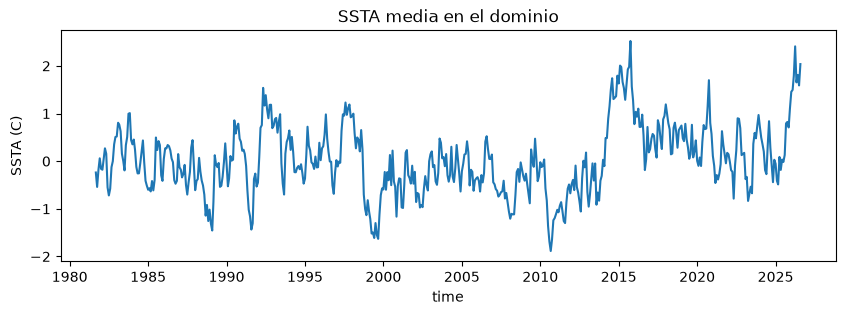

In [22]:
ssta_mean.plot(figsize=(10,3))
plt.ylabel('SSTA (C)')
plt.title('SSTA media en el dominio')
plt.show()

In [23]:
ssta_meantime = ds.ssta.mean(dim=('time'), skipna=True)    

In [24]:
ssta_meantime

<xarray.DataArray 'ssta' (lat: 58, lon: 66)> Size: 15kB
array([[-9.2484439e-03, -4.8047067e-03,  2.5385398e-05, ...,
        -5.0304808e-02, -5.7962772e-02, -6.5422907e-02],
       [-1.0324722e-02, -7.7383714e-03, -5.0665289e-03, ...,
        -4.1960016e-02, -5.0069969e-02, -6.0191523e-02],
       [-1.1130018e-02, -1.0793997e-02, -1.1174449e-02, ...,
        -3.2861620e-02, -3.9961003e-02, -4.9128756e-02],
       ...,
       [ 3.5204645e-02,  4.1233264e-02,  4.5996293e-02, ...,
                   nan,            nan,            nan],
       [ 3.4073580e-02,  4.1726138e-02,  4.7057137e-02, ...,
                   nan,            nan,            nan],
       [ 3.0657748e-02,  3.7676487e-02,  4.2875055e-02, ...,
                   nan,            nan,            nan]],
      shape=(58, 66), dtype=float32)
Coordinates:
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...

In [25]:
ssta_mean


<xarray.DataArray 'ssta' (time: 540)> Size: 2kB
array([-2.37494111e-01, -5.40169060e-01, -1.79166093e-01,  5.99263199e-02,
       -1.61783844e-01, -1.78843021e-01,  3.00070662e-02,  2.70233393e-01,
        1.55271634e-01, -5.49857914e-01, -7.19233990e-01, -5.78685820e-01,
       -1.24248534e-01, -4.15379822e-04,  3.53220195e-01,  5.07466316e-01,
        5.18841982e-01,  8.06495488e-01,  7.64832735e-01,  6.27807796e-01,
        1.58167064e-01,  6.39491621e-03, -1.93227753e-01,  3.36776078e-01,
        5.09085715e-01,  9.95600820e-01,  1.00861561e+00,  4.44950908e-01,
        3.53603214e-01,  4.54594284e-01,  2.41201788e-01, -1.19668178e-01,
       -2.56505489e-01, -2.54707992e-01, -4.68262248e-02,  1.98971316e-01,
        4.35364634e-01, -2.17254572e-02, -4.11490232e-01, -5.13221025e-01,
       -5.99809766e-01, -5.67858458e-01, -6.34811819e-01, -4.17231649e-01,
       -6.12196028e-01, -3.92144084e-01,  4.96980727e-01,  2.34920800e-01,
        4.21039045e-01,  3.37391734e-01, -2.96867132e-01, -4.12461102e-01,
        4.98505868e-02,  2.68243492e-01,  2.67679811e-01,  3.39075714e-01,
        3.15292537e-01,  2.28611648e-01,  5.59176244e-02, -2.10662000e-02,
       -3.98543358e-01, -4.73016679e-01, -4.12843972e-01,  1.48443997e-01,
       -1.28040001e-01, -1.79525018e-01, -3.40197295e-01, -2.66967535e-01,
       -7.76457191e-02, -4.99256104e-01, -7.00155377e-01, -4.41712260e-01,
       -2.25879118e-01,  2.85151124e-01,  4.41357315e-01, -8.33022743e-02,
       -6.08386397e-01, -4.15381819e-01, -3.75201732e-01,  6.95322156e-02,
...
        4.05404240e-01,  7.58456826e-01,  6.73803687e-01,  6.84572339e-01,
        1.14291215e+00,  1.70002079e+00,  8.01110089e-01,  5.71564376e-01,
        1.09133139e-01, -9.65483114e-02, -4.57140386e-01, -2.91161597e-01,
       -3.84866804e-01, -2.62812316e-01, -6.35059550e-02,  6.29502535e-01,
        3.47957760e-01,  1.61637276e-01, -4.44217063e-02,  1.75181687e-01,
        1.44076943e-01, -1.48471165e-02, -1.87410608e-01, -2.23288223e-01,
       -7.85682440e-01, -8.99293348e-02,  2.31322318e-01,  9.00114834e-01,
        8.89283121e-01,  6.93017185e-01,  1.27327293e-01,  1.51271239e-01,
        1.75097421e-01, -3.76160830e-01, -3.29556584e-01, -8.34015131e-01,
       -6.91987932e-01, -5.35391629e-01, -6.73400819e-01,  3.62828612e-01,
        5.93379021e-01,  4.79594558e-01,  7.41939664e-01,  9.69070196e-01,
        7.17731774e-01,  4.95015681e-01,  3.59847844e-01,  2.02412933e-01,
       -1.87494516e-01, -2.71881133e-01,  3.18795592e-01,  8.39271784e-01,
        2.82461822e-01, -7.79530630e-02, -4.40506697e-01,  3.01693641e-02,
       -5.39549515e-02, -4.13109571e-01, -4.87820774e-01,  8.92149657e-02,
       -1.82856739e-01,  3.47522274e-02, -1.63092241e-02,  1.29908428e-01,
        7.92041600e-01,  8.23573649e-01,  7.08574057e-01,  1.10878265e+00,
        1.45608079e+00,  1.49633324e+00,  1.78969634e+00,  2.41009378e+00,
        1.65437198e+00,  1.81057000e+00,  1.59055996e+00,  2.03786254e+00],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...

In [28]:
ssta_mean.attrs["long_name"] = "Promedio espacial ssat"

In [27]:
ssta_mean

<xarray.DataArray 'ssta' (time: 540)> Size: 2kB
array([-2.37494111e-01, -5.40169060e-01, -1.79166093e-01,  5.99263199e-02,
       -1.61783844e-01, -1.78843021e-01,  3.00070662e-02,  2.70233393e-01,
        1.55271634e-01, -5.49857914e-01, -7.19233990e-01, -5.78685820e-01,
       -1.24248534e-01, -4.15379822e-04,  3.53220195e-01,  5.07466316e-01,
        5.18841982e-01,  8.06495488e-01,  7.64832735e-01,  6.27807796e-01,
        1.58167064e-01,  6.39491621e-03, -1.93227753e-01,  3.36776078e-01,
        5.09085715e-01,  9.95600820e-01,  1.00861561e+00,  4.44950908e-01,
        3.53603214e-01,  4.54594284e-01,  2.41201788e-01, -1.19668178e-01,
       -2.56505489e-01, -2.54707992e-01, -4.68262248e-02,  1.98971316e-01,
        4.35364634e-01, -2.17254572e-02, -4.11490232e-01, -5.13221025e-01,
       -5.99809766e-01, -5.67858458e-01, -6.34811819e-01, -4.17231649e-01,
       -6.12196028e-01, -3.92144084e-01,  4.96980727e-01,  2.34920800e-01,
        4.21039045e-01,  3.37391734e-01, -2.96867132e-01, -4.12461102e-01,
        4.98505868e-02,  2.68243492e-01,  2.67679811e-01,  3.39075714e-01,
        3.15292537e-01,  2.28611648e-01,  5.59176244e-02, -2.10662000e-02,
       -3.98543358e-01, -4.73016679e-01, -4.12843972e-01,  1.48443997e-01,
       -1.28040001e-01, -1.79525018e-01, -3.40197295e-01, -2.66967535e-01,
       -7.76457191e-02, -4.99256104e-01, -7.00155377e-01, -4.41712260e-01,
       -2.25879118e-01,  2.85151124e-01,  4.41357315e-01, -8.33022743e-02,
       -6.08386397e-01, -4.15381819e-01, -3.75201732e-01,  6.95322156e-02,
...
        4.05404240e-01,  7.58456826e-01,  6.73803687e-01,  6.84572339e-01,
        1.14291215e+00,  1.70002079e+00,  8.01110089e-01,  5.71564376e-01,
        1.09133139e-01, -9.65483114e-02, -4.57140386e-01, -2.91161597e-01,
       -3.84866804e-01, -2.62812316e-01, -6.35059550e-02,  6.29502535e-01,
        3.47957760e-01,  1.61637276e-01, -4.44217063e-02,  1.75181687e-01,
        1.44076943e-01, -1.48471165e-02, -1.87410608e-01, -2.23288223e-01,
       -7.85682440e-01, -8.99293348e-02,  2.31322318e-01,  9.00114834e-01,
        8.89283121e-01,  6.93017185e-01,  1.27327293e-01,  1.51271239e-01,
        1.75097421e-01, -3.76160830e-01, -3.29556584e-01, -8.34015131e-01,
       -6.91987932e-01, -5.35391629e-01, -6.73400819e-01,  3.62828612e-01,
        5.93379021e-01,  4.79594558e-01,  7.41939664e-01,  9.69070196e-01,
        7.17731774e-01,  4.95015681e-01,  3.59847844e-01,  2.02412933e-01,
       -1.87494516e-01, -2.71881133e-01,  3.18795592e-01,  8.39271784e-01,
        2.82461822e-01, -7.79530630e-02, -4.40506697e-01,  3.01693641e-02,
       -5.39549515e-02, -4.13109571e-01, -4.87820774e-01,  8.92149657e-02,
       -1.82856739e-01,  3.47522274e-02, -1.63092241e-02,  1.29908428e-01,
        7.92041600e-01,  8.23573649e-01,  7.08574057e-01,  1.10878265e+00,
        1.45608079e+00,  1.49633324e+00,  1.78969634e+00,  2.41009378e+00,
        1.65437198e+00,  1.81057000e+00,  1.59055996e+00,  2.03786254e+00],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...
    description:   Promedio espacial ssat

In [30]:
baja_norte.isel(time=0).plot()

NameError: name 'baja_norte' is not defined

In [41]:
baja_norte = ds.ssta.sel(lat=slice(28,33), lon=slice(-120,-115))

In [33]:
baja_norte

<xarray.DataArray 'sst' (time: 540, lat: 20, lon: 20)> Size: 864kB
[216000 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 80B 28.12 28.38 28.62 28.88 ... 32.38 32.62 32.88
  * lon      (lon) float32 80B -119.9 -119.6 -119.4 ... -115.6 -115.4 -115.1
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

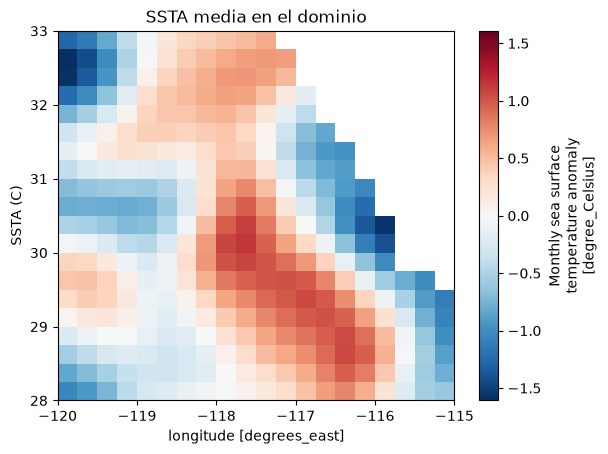

In [42]:
baja_norte.isel(time=0).plot()
plt.ylabel('SSTA (C)')
plt.title('SSTA media en el dominio')
plt.show()

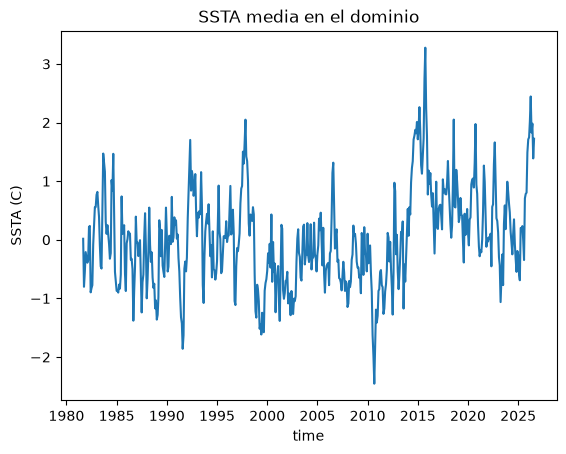

In [43]:
baja_norte.mean(dim=('lat','lon'), skipna=True).plot()
plt.ylabel('SSTA (C)')
plt.title('SSTA media en el dominio')
plt.show()

In [45]:
ssta_series=ssta_mean.to_series()

In [46]:
type(ssta_series)

pandas.Series

In [55]:
oni = pd.read_csv("../data/oni_mensual_1981_2026.csv", parse_dates=['time'])
rain = pd.read_csv("../data/precipitacion_ensenada_1981_2026.csv", parse_dates=['time'])
oni = oni.set_index('time')
rain = rain.set_index('time')

In [56]:
analysis = pd.concat(
    [
        ssta_series.rename("ssta_degC"),
        oni["oni_degC"],
        rain["precip_mm"]
    ],
    axis=1
)
analysis.head()

,ssta_degC,oni_degC,precip_mm
time,,,
1981-09-01,-0.237494,-0.25,2.0
1981-10-01,-0.540169,-0.16,5.0
1981-11-01,-0.179166,-0.13,68.5
1981-12-01,0.059926,-0.15,20.0
1982-01-01,-0.161784,-0.08,54.8


In [53]:
oni

,oni_degC
time,
1981-09-01,-0.25
1981-10-01,-0.16
1981-11-01,-0.13
1981-12-01,-0.15
1982-01-01,-0.08
...,...
2026-04-01,0.11
2026-05-01,0.46
2026-06-01,0.95


In [54]:
rain

,oni_degC
time,
1981-09-01,-0.25
1981-10-01,-0.16
1981-11-01,-0.13
1981-12-01,-0.15
1982-01-01,-0.08
...,...
2026-04-01,0.11
2026-05-01,0.46
2026-06-01,0.95


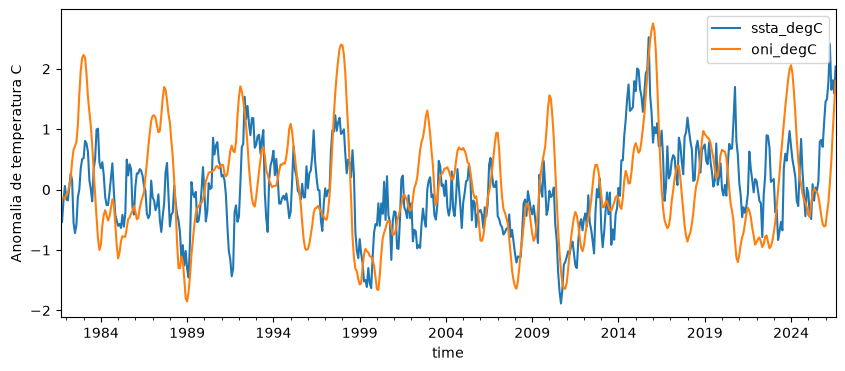

In [57]:
analysis[["ssta_degC", "oni_degC"]].plot(figsize=(10,4))
plt.ylabel("Anomalia de temperatura C")
plt.show()

[]

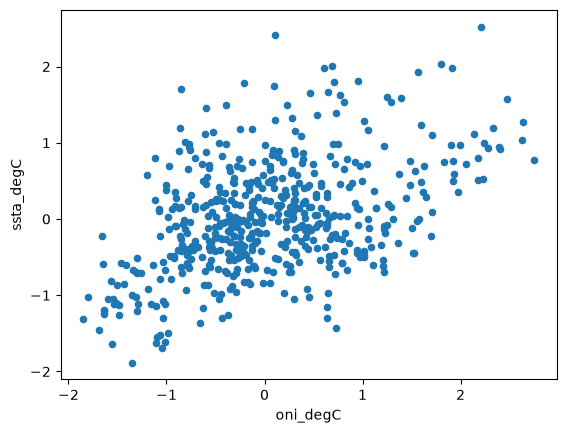

In [61]:
analysis.plot.scatter(x='oni_degC', y='ssta_degC').plot(figsize=(5,5))
                                                        
                                                    

In [62]:
analysis[['oni_degC','ssta_degC']].corr()

,oni_degC,ssta_degC
oni_degC,1.00000,0.45218
ssta_degC,0.45218,1.00000


In [63]:
def regional_mean(da,lat_range, lon_range):
    """Calcula la media espacial de un DataArray en una region rectangular.
    Parameters
    ------------
    da : xarray.Datarray
         Campo con dimensiones lat y lon
    lat_range : tuple
        (lat_min,lat_max)
    lon_range : tuple
        (lon_min, lon_max)
        
    Returns
    ------------
    xarray.DataArray
        Serie resultante despues de promediar lat y lon.
    """
    region = da.sel(lat=slice(*lat_range), lon=slice(*lon_range))

    return(region.mean(dim=('lat', 'lon'), skipna=True))

In [65]:
baja_series = regional_mean(ds.ssta, (28,33),(-120,-115))

In [66]:
baja_series

<xarray.DataArray 'ssta' (time: 540)> Size: 2kB
array([ 1.74564160e-02, -8.01558197e-01, -5.48438787e-01, -2.10056201e-01,
       -3.00844878e-01, -3.91321152e-01, -3.51450324e-01,  2.18306631e-01,
        2.36718208e-01, -8.96373689e-01, -8.26660514e-01, -7.74362922e-01,
       -8.32917541e-02,  2.16435254e-01,  5.55345178e-01,  5.58817208e-01,
        7.67568827e-01,  8.17435920e-01,  5.92509389e-01,  3.92195582e-01,
       -8.96406993e-02, -4.53420550e-01, -4.91134137e-01,  4.46056247e-01,
        1.47094560e+00,  1.31415939e+00,  1.16202915e+00,  3.07478607e-01,
        1.01089582e-01,  2.49819666e-01,  9.59187672e-02, -7.72193447e-02,
       -3.22561711e-01, -2.27311581e-01,  1.01847410e+00,  8.41802597e-01,
        1.46675611e+00,  4.73688900e-01, -5.48028052e-01, -7.17218101e-01,
       -8.69918585e-01, -8.71838868e-01, -9.00755703e-01, -7.64285564e-01,
       -8.32358479e-01, -5.95172942e-01,  7.39920318e-01,  1.02240585e-01,
        1.37973234e-01,  2.48553261e-01, -5.81110537e-01, -8.74161959e-01,
       -5.98022267e-02,  1.37858000e-02,  1.45766810e-01,  1.06481969e-01,
        1.07414640e-01, -3.40419650e-01, -3.23842049e-01, -4.98340487e-01,
       -1.37972903e+00, -8.75574112e-01, -4.53465253e-01,  3.95062685e-01,
       -4.71810848e-02, -4.68279608e-02, -2.77384013e-01, -1.24894202e-01,
       -6.47406606e-03, -6.33568466e-01, -1.23914349e+00, -7.22683966e-01,
       -5.93612790e-01,  3.84082384e-02,  4.53453034e-01, -1.12486862e-01,
       -9.98680532e-01, -6.73011720e-01, -2.05730632e-01,  5.48982501e-01,
...
        9.45368707e-01,  1.02782607e+00,  1.04618251e+00,  8.91335964e-01,
        1.31337094e+00,  1.97421849e+00,  9.42699850e-01,  7.82236397e-01,
        2.48114347e-01, -1.15848340e-01, -2.80837715e-01, -1.76299915e-01,
       -2.12682039e-01,  8.36434774e-03,  4.68366623e-01,  1.26603842e+00,
        9.86229181e-01,  4.25968647e-01, -1.18900582e-01,  2.46720091e-02,
       -3.01908590e-02,  4.35215198e-02,  2.52360944e-02,  1.03148624e-01,
       -4.52163190e-01,  5.62318325e-01,  6.03779495e-01,  1.29020143e+00,
        1.66140044e+00,  9.86985683e-01,  3.67624372e-01,  3.21864456e-01,
        1.28840417e-01, -2.97220111e-01, -4.33409423e-01, -1.06257606e+00,
       -6.39319062e-01, -2.51341134e-01, -7.72708714e-01,  2.68216729e-01,
        5.86270988e-01,  1.81181297e-01,  6.09207451e-01,  9.90591884e-01,
        8.24549317e-01,  6.18465662e-01,  4.67631251e-01,  1.33606359e-01,
       -4.22421023e-02, -2.48348311e-01,  9.76257995e-02,  3.48739564e-01,
       -7.58259296e-02, -3.32571298e-01, -5.47031045e-01, -1.91240966e-01,
       -2.62534738e-01, -5.87881923e-01, -6.90237880e-01,  1.99982464e-01,
        1.95412084e-01,  2.33372405e-01, -7.88965728e-04, -3.45169932e-01,
        7.07026303e-01,  7.82383800e-01,  8.04951608e-01,  1.49029386e+00,
        1.71222687e+00,  1.74768174e+00,  2.01705718e+00,  2.44491124e+00,
        1.82997346e+00,  1.98151922e+00,  1.38823926e+00,  1.72411776e+00],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...